### Task 1: Designing a Heuristic for a Warehouse Robot

In [1]:
import math
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd

# 1. Coordinates of warehouse locations
locations = {
    "Receiving_Area": (0, 0),
    "Storage_A": (2, 1),
    "Storage_B": (1, 4),
    "Sorting_Area": (4, 2),
    "Inspection_Area": (5, 5),
    "Packing_Station": (7, 6)
}

# 2. Weighted warehouse graph
warehouse_graph = {
    "Receiving_Area": {"Storage_A": 2.2, "Storage_B": 4.1},
    "Storage_A": {"Sorting_Area": 2.2},
    "Storage_B": {"Inspection_Area": 5.0, "Sorting_Area": 6.0},
    "Sorting_Area": {"Inspection_Area": 3.2, "Packing_Station": 5.0},
    "Inspection_Area": {"Packing_Station": 2.2},
    "Packing_Station": {}
}

# 3. Euclidean heuristic
def heuristic(current, goal):
    x1, y1 = locations[current]
    x2, y2 = locations[goal]
    return math.sqrt((x1 - x2) ** 2 + (y1 - y2) ** 2)

# 4. Calculate heuristic values
goal = "Packing_Station"
print("Heuristic Values")
print("----------------")
h_table = pd.DataFrame(
    [{"Location": loc, "Coordinates": locations[loc], "h(n)": round(heuristic(loc, goal), 2)} for loc in locations]
)
print(h_table.to_string(index=False))

Heuristic Values
----------------
       Location Coordinates  h(n)
 Receiving_Area      (0, 0)  9.22
      Storage_A      (2, 1)  7.07
      Storage_B      (1, 4)  6.32
   Sorting_Area      (4, 2)  5.00
Inspection_Area      (5, 5)  2.24
Packing_Station      (7, 6)  0.00


**Why Euclidean distance is a suitable heuristic:** the robot moves between physical locations that have coordinates, and the straight-line distance is the shortest possible distance between two points. Real routes are normally at least this long, so h(n) is usually a safe (admissible) underestimate of the remaining cost. It is also cheap to compute and uses only the stored coordinates.

#### NetworkX visualization: Since Task 1 does not ask GBFS/A* to find a path, we highlight the actual minimum-cost path merely for visualization:

In [2]:
# 5. Create NetworkX graph
G = nx.DiGraph()
for node, neighbors in warehouse_graph.items():
    G.add_node(node)
    for neighbor, cost in neighbors.items():
        G.add_edge(node, neighbor, weight=cost)

# 6. Find minimum-cost path (weighted shortest path)
solution_path = nx.shortest_path(G, source="Receiving_Area", target="Packing_Station", weight="weight")
solution_cost = nx.shortest_path_length(G, source="Receiving_Area", target="Packing_Station", weight="weight")

print("\nMinimum cost path:")
print(" -> ".join(solution_path))
print(f"Total cost: {solution_cost:.2f}")


Minimum cost path:
Receiving_Area -> Storage_A -> Sorting_Area -> Packing_Station
Total cost: 9.40


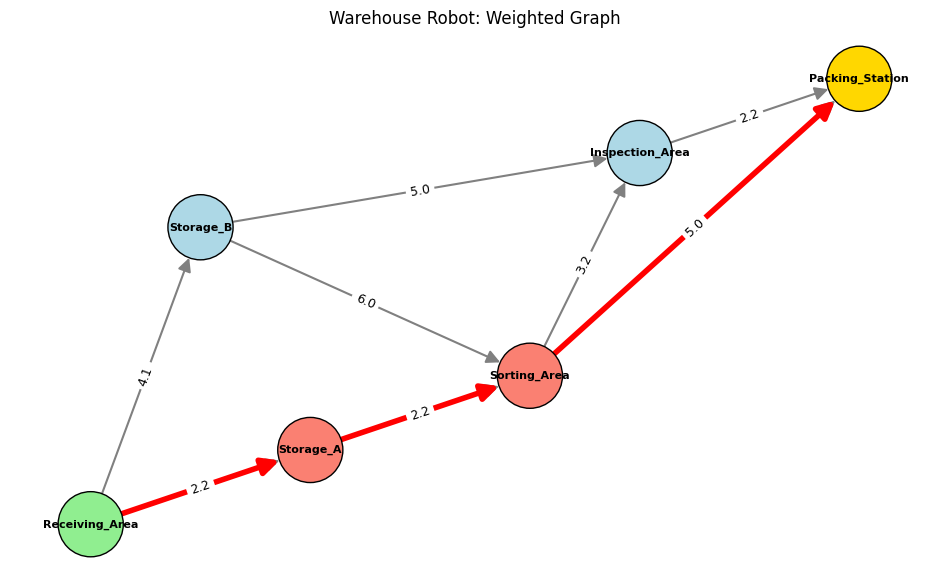

In [3]:
def draw_graph(G, pos, path, title, start, goal, figsize=(12, 7)):
    """Draw nodes, edges, weights; highlight the solution path in red."""
    plt.figure(figsize=figsize)
    path_edges = list(zip(path, path[1:]))
    colors = ["lightgreen" if n == start else "gold" if n == goal
              else "salmon" if n in path else "lightblue" for n in G.nodes]
    nx.draw_networkx_nodes(G, pos, node_color=colors, node_size=2200, edgecolors="black")
    nx.draw_networkx_labels(G, pos, font_size=8, font_weight="bold")
    nx.draw_networkx_edges(G, pos, edge_color="gray", arrows=True, arrowsize=20, node_size=2200, width=1.5)
    nx.draw_networkx_edges(G, pos, edgelist=path_edges, edge_color="red", width=4,
                           arrows=True, arrowsize=25, node_size=2200)
    nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "weight"), font_size=9)
    plt.title(title)
    plt.axis("off")
    plt.show()

# 7. Visualize graph
pos = locations
draw_graph(G, pos, solution_path, "Warehouse Robot: Weighted Graph", "Receiving_Area", "Packing_Station")

In [4]:
# 8. Verify heuristic condition h(n) <= cost(n,m) + h(m)
print("\nHeuristic Condition Verification")
print("***********************************")
all_ok = True
for node in warehouse_graph:
    for neighbor, cost in warehouse_graph[node].items():
        hn, hm = heuristic(node, goal), heuristic(neighbor, goal)
        ok = hn <= cost + hm + 1e-9
        all_ok &= ok
        print(f"{node:16s} -> {neighbor:16s} h(n)={hn:5.2f} <= cost({cost}) + h(m)={hm:5.2f} => {cost + hm:5.2f}  {'OK' if ok else 'VIOLATED'}")
print("\nHeuristic is consistent on all edges:", all_ok)


Heuristic Condition Verification
***********************************
Receiving_Area   -> Storage_A        h(n)= 9.22 <= cost(2.2) + h(m)= 7.07 =>  9.27  OK
Receiving_Area   -> Storage_B        h(n)= 9.22 <= cost(4.1) + h(m)= 6.32 => 10.42  OK
Storage_A        -> Sorting_Area     h(n)= 7.07 <= cost(2.2) + h(m)= 5.00 =>  7.20  OK
Storage_B        -> Inspection_Area  h(n)= 6.32 <= cost(5.0) + h(m)= 2.24 =>  7.24  OK
Storage_B        -> Sorting_Area     h(n)= 6.32 <= cost(6.0) + h(m)= 5.00 => 11.00  OK
Sorting_Area     -> Inspection_Area  h(n)= 5.00 <= cost(3.2) + h(m)= 2.24 =>  5.44  OK
Sorting_Area     -> Packing_Station  h(n)= 5.00 <= cost(5.0) + h(m)= 0.00 =>  5.00  OK
Inspection_Area  -> Packing_Station  h(n)= 2.24 <= cost(2.2) + h(m)= 0.00 =>  2.20  VIOLATED

Heuristic is consistent on all edges: False


**Observation:** h(n) ≤ cost(n,m) + h(m) holds for 7 of the 8 edges. The only violation is Inspection_Area → Packing_Station: the straight-line distance is 2.24 but the given edge cost is only 2.2, so the heuristic slightly overestimates there (by 0.04). The Euclidean heuristic is therefore *nearly* consistent but not strictly consistent or admissible for this graph, because the edge costs in the lab are rounded below the true straight-line distance. This does not change the result here (the optimal path is Receiving_Area → Storage_A → Sorting_Area → Packing_Station, cost 9.4).

### Task 2: Greedy Best-First Search for Airport Baggage Handling

In [5]:
import math
import heapq
import networkx as nx
import matplotlib.pyplot as plt

# 1. Airport coordinates
locations = {
    "Baggage_Area": (0, 0),
    "Security": (2, 1),
    "Checkpoint": (1, 4),
    "Food_Court": (4, 2),
    "Terminal_Hall": (5, 5),
    "Departure_Gate": (8, 6)
}

# 2. Weighted graph
airport_graph = {
    "Baggage_Area": {"Security": 2.2, "Checkpoint": 4.1},
    "Security": {"Food_Court": 2.2},
    "Checkpoint": {"Terminal_Hall": 5.0},
    "Food_Court": {"Terminal_Hall": 3.2, "Departure_Gate": 6.0},
    "Terminal_Hall": {"Departure_Gate": 3.2},
    "Departure_Gate": {}
}

# 3. Euclidean heuristic
def heuristic(current, goal):
    x1, y1 = locations[current]
    x2, y2 = locations[goal]
    return math.sqrt((x1 - x2) ** 2 + (y1 - y2) ** 2)

# 4. GBFS  (f(n) = h(n))
def greedy_best_first_search(start, goal, graph):
    frontier = [(heuristic(start, goal), start)]   # min-heap ordered by h(n)
    came_from = {}
    visited = set()
    in_frontier = {start}
    expansion_order = []

    while frontier:
        h, current = heapq.heappop(frontier)
        if current in visited:
            continue
        visited.add(current)
        expansion_order.append(current)

        if current == goal:
            break

        for neighbor in graph[current]:
            if neighbor not in visited and neighbor not in in_frontier:
                came_from[neighbor] = current
                in_frontier.add(neighbor)
                heapq.heappush(frontier, (heuristic(neighbor, goal), neighbor))
    else:
        return None, None, expansion_order

    # Reconstruct path
    path = [goal]
    while path[-1] in came_from:
        path.append(came_from[path[-1]])
    path.reverse()

    # Calculate actual path cost
    total_cost = sum(graph[a][b] for a, b in zip(path, path[1:]))
    return path, total_cost, expansion_order

# 5. Run GBFS
start = "Baggage_Area"
goal = "Departure_Gate"
path, total_cost, expansion_order = greedy_best_first_search(start, goal, airport_graph)

print("GBFS")
print("--------------------------------")
print("Expansion order:")
print(" -> ".join(expansion_order))

print("\nSolution path:")
print(" -> ".join(path))

print(f"\nTotal path cost: {total_cost:.2f}")
print("\nHeuristic values h(n) to Departure_Gate:")
for n in locations:
    print(f"  {n:15s} {heuristic(n, goal):.2f}")

GBFS
--------------------------------
Expansion order:
Baggage_Area -> Checkpoint -> Terminal_Hall -> Departure_Gate

Solution path:
Baggage_Area -> Checkpoint -> Terminal_Hall -> Departure_Gate

Total path cost: 12.30

Heuristic values h(n) to Departure_Gate:
  Baggage_Area    10.00
  Security        7.81
  Checkpoint      7.28
  Food_Court      5.66
  Terminal_Hall   3.16
  Departure_Gate  0.00


#### NetworkX visualization

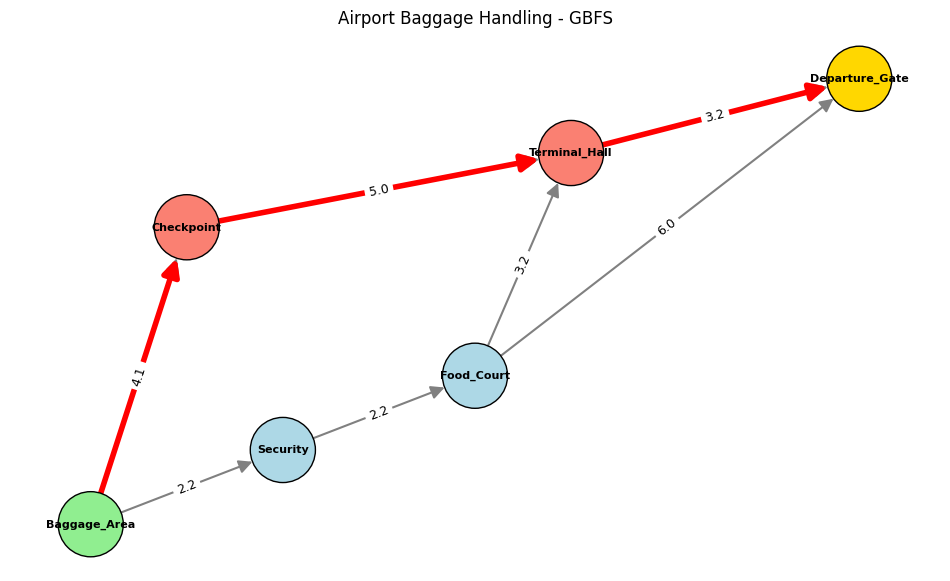

In [6]:
def draw_graph(G, pos, path, title, start, goal, figsize=(12, 7)):
    """Draw nodes, edges, weights; highlight the solution path in red."""
    plt.figure(figsize=figsize)
    path_edges = list(zip(path, path[1:]))
    colors = ["lightgreen" if n == start else "gold" if n == goal
              else "salmon" if n in path else "lightblue" for n in G.nodes]
    nx.draw_networkx_nodes(G, pos, node_color=colors, node_size=2200, edgecolors="black")
    nx.draw_networkx_labels(G, pos, font_size=8, font_weight="bold")
    nx.draw_networkx_edges(G, pos, edge_color="gray", arrows=True, arrowsize=20, node_size=2200, width=1.5)
    nx.draw_networkx_edges(G, pos, edgelist=path_edges, edge_color="red", width=4,
                           arrows=True, arrowsize=25, node_size=2200)
    nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "weight"), font_size=9)
    plt.title(title)
    plt.axis("off")
    plt.show()

# 6. NetworkX visualization
G = nx.DiGraph()
for node, neighbors in airport_graph.items():
    G.add_node(node)
    for neighbor, cost in neighbors.items():
        G.add_edge(node, neighbor, weight=cost)

pos = locations
draw_graph(G, pos, path, "Airport Baggage Handling - GBFS", start, goal)

**Why GBFS selected the nodes in that order:** GBFS looks only at h(n), the straight-line distance to Departure_Gate. From Baggage_Area it could go to Security (h = 7.81) or Checkpoint (h = 7.28). Checkpoint looks closer to the gate, so it is expanded first. From Checkpoint the only move is Terminal_Hall (h = 3.16), and from there the gate is reached.

**Result:** the path is Baggage_Area → Checkpoint → Terminal_Hall → Departure_Gate with cost 12.3. This is **not optimal**: Baggage_Area → Security → Food_Court → Departure_Gate costs only 10.4. GBFS is fast but ignores the cost already travelled (the 4.1 + 5.0 edges), so it can be misled by a heuristic that looks attractive.

### Task 3: A* Search for Emergency Supply Robot

In [7]:
import math
import heapq
import networkx as nx
import matplotlib.pyplot as plt

# 1. Hospital coordinates
locations = {
    "Pharmacy": (0, 0),
    "Main_Corridor": (2, 1),
    "Patient_Wing": (1, 4),
    "Nursing_Station": (4, 2),
    "Laboratory": (5, 5),
    "Emergency_Ward": (8, 6)
}

# 2. Hospital weighted graph
hospital_graph = {
    "Pharmacy": {"Main_Corridor": 2.2, "Patient_Wing": 4.1},
    "Main_Corridor": {"Nursing_Station": 2.2},
    "Patient_Wing": {"Laboratory": 5.0},
    "Nursing_Station": {"Laboratory": 3.2, "Emergency_Ward": 6.0},
    "Laboratory": {"Emergency_Ward": 3.2},
    "Emergency_Ward": {}
}

# 3. Euclidean heuristic
def heuristic(current, goal):
    x1, y1 = locations[current]
    x2, y2 = locations[goal]
    return math.sqrt((x1 - x2) ** 2 + (y1 - y2) ** 2)

# 4. Path reconstruction
def reconstruct_path(came_from, current):
    path = [current]
    while current in came_from:
        current = came_from[current]
        path.append(current)
    path.reverse()
    return path

# 5. A* Search  f(n) = g(n) + h(n)
def a_star_search(start, goal, graph):
    frontier = [(heuristic(start, goal), start)]   # (f, node)
    g_cost = {start: 0.0}
    came_from = {}
    closed = set()
    expansion_order = []

    while frontier:
        f, current = heapq.heappop(frontier)
        if current in closed:
            continue
        closed.add(current)
        expansion_order.append(current)

        if current == goal:
            path = reconstruct_path(came_from, current)
            return path, g_cost[current], expansion_order, g_cost

        for neighbor, cost in graph[current].items():
            new_g = g_cost[current] + cost
            if neighbor not in g_cost or new_g < g_cost[neighbor]:
                g_cost[neighbor] = new_g
                came_from[neighbor] = current
                heapq.heappush(frontier, (new_g + heuristic(neighbor, goal), neighbor))
    return None, None, expansion_order, g_cost

# 6. Run A*
start = "Pharmacy"
goal = "Emergency_Ward"
path, total_cost, expansion_order, g_cost = a_star_search(start, goal, hospital_graph)

print("A* Search")
print("--------------------------------")

print("Expansion order:")
print(" -> ".join(expansion_order))

print("\nSolution path:")
print(" -> ".join(path))

print(f"\nTotal path cost: {total_cost:.2f}")

A* Search
--------------------------------
Expansion order:
Pharmacy -> Main_Corridor -> Nursing_Station -> Emergency_Ward

Solution path:
Pharmacy -> Main_Corridor -> Nursing_Station -> Emergency_Ward

Total path cost: 10.40


#### g(n), h(n), f(n) table

In [8]:
print("\nA* Node Information")
print("*********************")
print(
    f"{'Node':20s}"
    f"{'g(n)':>10s}"
    f"{'h(n)':>10s}"
    f"{'f(n)':>10s}"
)

for node in expansion_order:
    g = g_cost[node]
    h = heuristic(node, goal)
    f = g + h
    print(
        f"{node:20s}"
        f"{g:10.2f}"
        f"{h:10.2f}"
        f"{f:10.2f}"
    )


A* Node Information
*********************
Node                      g(n)      h(n)      f(n)
Pharmacy                  0.00     10.00     10.00
Main_Corridor             2.20      7.81     10.01
Nursing_Station           4.40      5.66     10.06
Emergency_Ward           10.40      0.00     10.40


#### NetworkX visualization

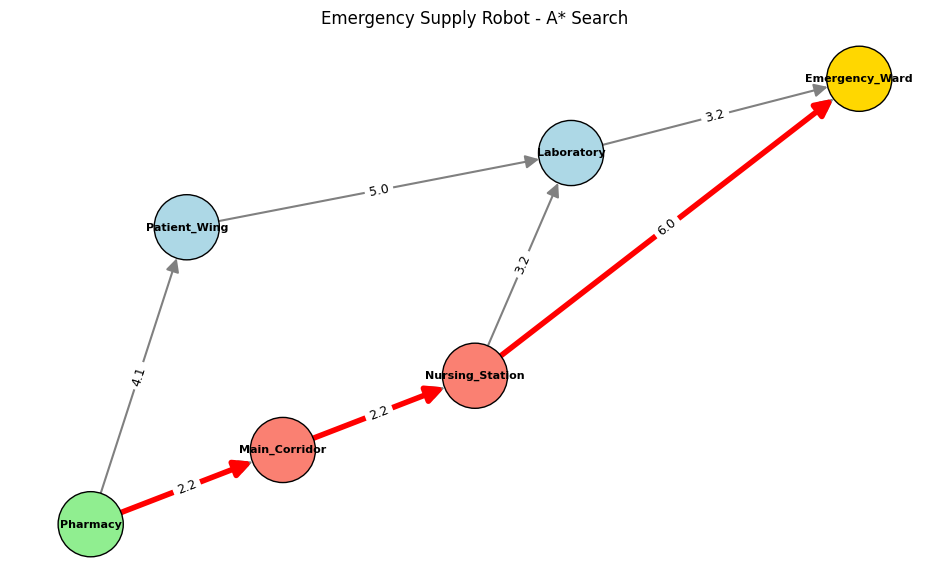

In [9]:
def draw_graph(G, pos, path, title, start, goal, figsize=(12, 7)):
    """Draw nodes, edges, weights; highlight the solution path in red."""
    plt.figure(figsize=figsize)
    path_edges = list(zip(path, path[1:]))
    colors = ["lightgreen" if n == start else "gold" if n == goal
              else "salmon" if n in path else "lightblue" for n in G.nodes]
    nx.draw_networkx_nodes(G, pos, node_color=colors, node_size=2200, edgecolors="black")
    nx.draw_networkx_labels(G, pos, font_size=8, font_weight="bold")
    nx.draw_networkx_edges(G, pos, edge_color="gray", arrows=True, arrowsize=20, node_size=2200, width=1.5)
    nx.draw_networkx_edges(G, pos, edgelist=path_edges, edge_color="red", width=4,
                           arrows=True, arrowsize=25, node_size=2200)
    nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "weight"), font_size=9)
    plt.title(title)
    plt.axis("off")
    plt.show()

# 7. NetworkX visualization
G = nx.DiGraph()
for node, neighbors in hospital_graph.items():
    G.add_node(node)
    for neighbor, cost in neighbors.items():
        G.add_edge(node, neighbor, weight=cost)

pos = locations
draw_graph(G, pos, path, "Emergency Supply Robot - A* Search", start, goal)

GBFS would primarily ask:

"Which node appears closest to the Emergency Ward?"

A* instead asks:

"Considering both the cost already travelled and the estimated remaining cost, which node has the lowest estimated total cost?"

**Comparison on this graph:** GBFS (start Pharmacy, goal Emergency_Ward) picks Patient_Wing first because h = 7.28 is lower than Main_Corridor's h = 7.81, and ends with cost 12.3 (Pharmacy → Patient_Wing → Laboratory → Emergency_Ward). A* adds g(n): Main_Corridor has f = 2.2 + 7.81 = 10.01 versus Patient_Wing f = 4.1 + 7.28 = 11.38, so A* goes through Main_Corridor and Nursing_Station and finds the optimal path with cost 10.4. Considering g(n) stops A* being lured by nodes that look close but were expensive to reach; the trade-off is that A* may expand more nodes than GBFS in general.

### Task 4: Weighted A* for Autonomous Delivery Drone

In [10]:
import math
import heapq
import pandas as pd

# 1. Location Coordinates
locations = {
    "Distribution_Center": (0, 0),
    "Zone_A": (2, 1),
    "Zone_B": (1, 4),
    "Zone_C": (4, 2),
    "Zone_D": (5, 5),
    "Customer_Building": (8, 6)
}

# 2. Weighted Graph
graph = {
    "Distribution_Center": {"Zone_A": 2.2, "Zone_B": 3.0},
    "Zone_A": {"Zone_C": 2.2},
    "Zone_B": {"Zone_D": 5.0},
    "Zone_C": {"Zone_D": 3.2, "Customer_Building": 6.0},
    "Zone_D": {"Customer_Building": 3.2},
    "Customer_Building": {}
}

# 3. Euclidean Heuristic
def heuristic(node, goal):
    x1, y1 = locations[node]
    x2, y2 = locations[goal]
    return math.sqrt((x1 - x2) ** 2 + (y1 - y2) ** 2)

# 4. Display Heuristic Values
goal = "Customer_Building"
heuristic_data = []
for node in locations:
    heuristic_data.append({"Node": node, "h(n)": round(heuristic(node, goal), 2)})
heuristic_df = pd.DataFrame(heuristic_data)
print("Heuristic Values:")
print(heuristic_df.to_string(index=False))

# 5. Weighted A* Search
# f(n) = g(n) + w * h(n)   (w = 1 gives normal A*)
def weighted_a_star(start, goal, graph, weight):
    frontier = [(weight * heuristic(start, goal), start)]
    g_cost = {start: 0.0}
    came_from = {}
    closed = set()
    expansion_order = []

    while frontier:
        f, current = heapq.heappop(frontier)
        if current in closed:
            continue
        closed.add(current)
        expansion_order.append(current)

        if current == goal:
            path = [current]
            while current in came_from:
                current = came_from[current]
                path.append(current)
            path.reverse()
            return path, g_cost[goal], expansion_order

        for neighbor, cost in graph[current].items():
            new_g = g_cost[current] + cost
            if neighbor not in g_cost or new_g < g_cost[neighbor]:
                g_cost[neighbor] = new_g
                came_from[neighbor] = current
                heapq.heappush(frontier, (new_g + weight * heuristic(neighbor, goal), neighbor))
    return None, None, expansion_order

# 6. Run Weighted A* for All Required Weights
start = "Distribution_Center"
goal = "Customer_Building"
weights = [1, 1.5, 2, 3]
results = []

for w in weights:
    path, cost, expansion_order = weighted_a_star(start, goal, graph, w)
    results.append({
        "Weight": w,
        "Solution Path": " → ".join(path),
        "Total Cost": round(cost, 2),
        "Nodes Expanded": len(expansion_order),
        "Expansion Order": " → ".join(expansion_order)
    })

# 7. Display Results in dataframe
results_df = pd.DataFrame(results)
print("\nWeighted A* Results")
print(results_df[["Weight", "Solution Path", "Total Cost", "Nodes Expanded"]].to_string(index=False))

# 8. Display Detailed Expansion Orders
print("\nDetailed Expansion Orders")
print("-------------------------")
for r in results:
    print(f"w = {r['Weight']}: {r['Expansion Order']}")

Heuristic Values:
               Node  h(n)
Distribution_Center 10.00
             Zone_A  7.81
             Zone_B  7.28
             Zone_C  5.66
             Zone_D  3.16
  Customer_Building  0.00

Weighted A* Results
 Weight                                             Solution Path  Total Cost  Nodes Expanded
    1.0 Distribution_Center → Zone_A → Zone_C → Customer_Building        10.4               5
    1.5 Distribution_Center → Zone_A → Zone_C → Customer_Building        10.4               4
    2.0 Distribution_Center → Zone_B → Zone_D → Customer_Building        11.2               4
    3.0 Distribution_Center → Zone_B → Zone_D → Customer_Building        11.2               4

Detailed Expansion Orders
-------------------------
w = 1: Distribution_Center → Zone_A → Zone_C → Zone_B → Customer_Building
w = 1.5: Distribution_Center → Zone_A → Zone_C → Customer_Building
w = 2: Distribution_Center → Zone_B → Zone_D → Customer_Building
w = 3: Distribution_Center → Zone_B → Zone_D → Cus

#### NetworkX visualization

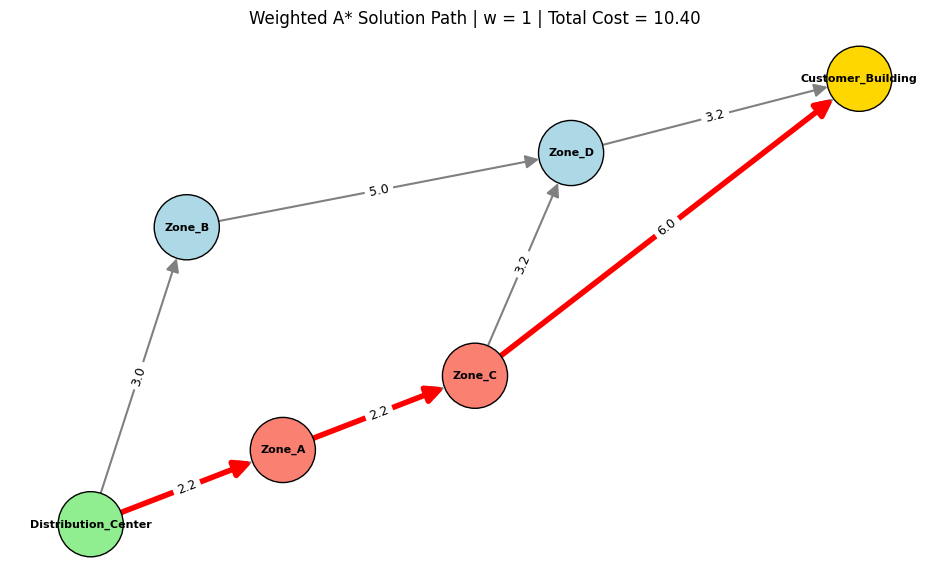

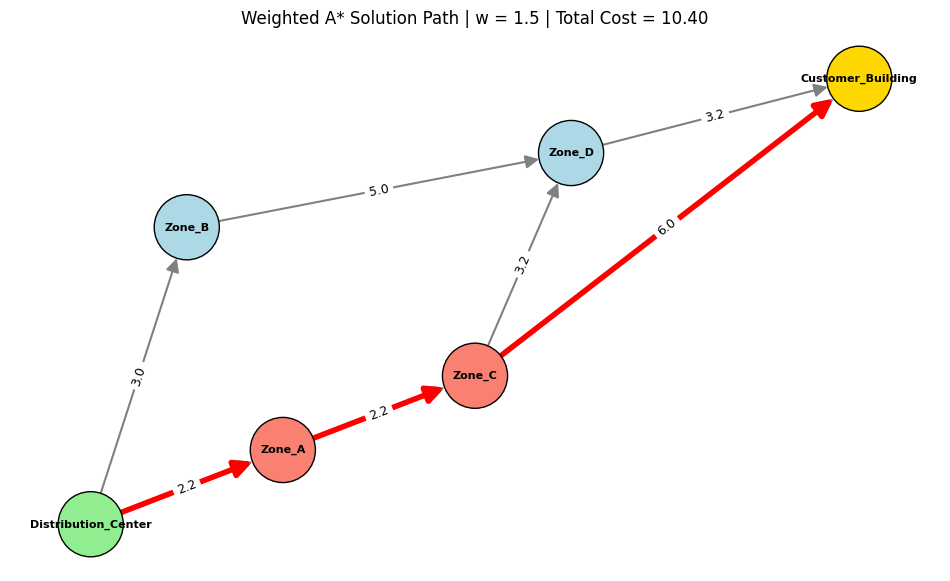

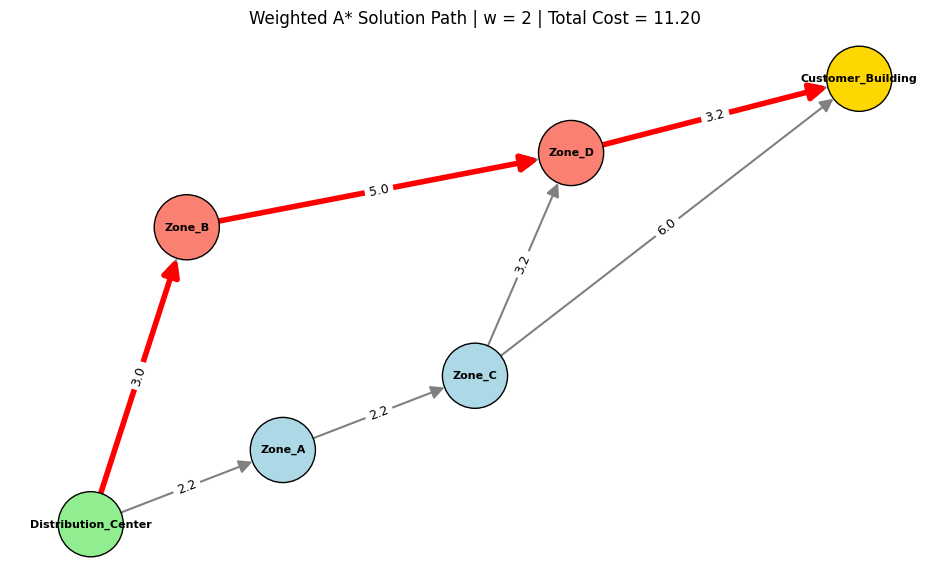

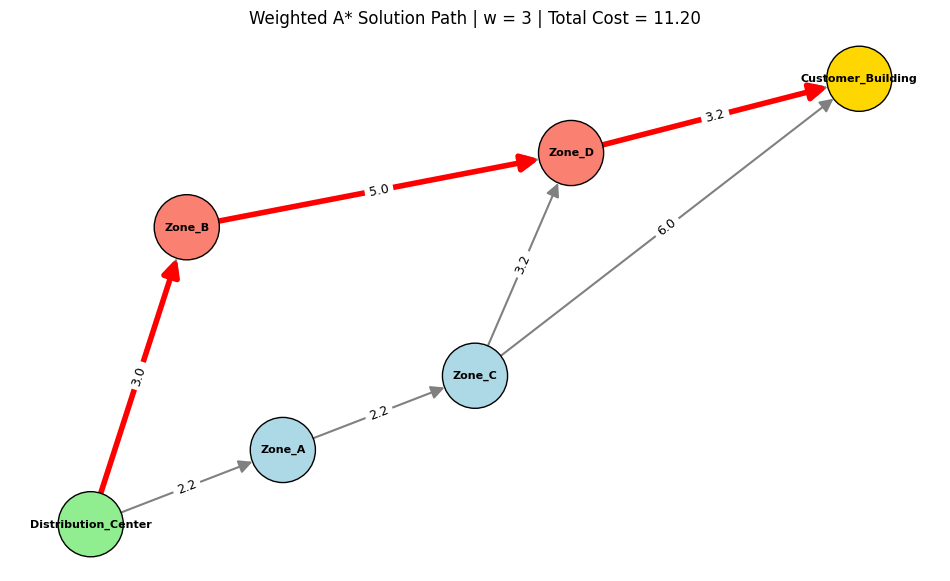

In [11]:
import networkx as nx
import matplotlib.pyplot as plt

# 1. Create NetworkX Graph
G = nx.DiGraph()
for node, position in locations.items():
    G.add_node(node, pos=position)
for node, neighbors in graph.items():
    for neighbor, cost in neighbors.items():
        G.add_edge(node, neighbor, weight=cost)

# 2. Node Positions
pos = locations

# 3. Visualize Weighted A* Result for Each Weight
for w in weights:
    path, cost, order = weighted_a_star(start, goal, graph, w)
    plt.figure(figsize=(12, 7))
    path_edges = list(zip(path, path[1:]))
    colors = ["lightgreen" if n == start else "gold" if n == goal
              else "salmon" if n in path else "lightblue" for n in G.nodes]
    nx.draw_networkx_nodes(G, pos, node_color=colors, node_size=2200, edgecolors="black")
    nx.draw_networkx_labels(G, pos, font_size=8, font_weight="bold")
    nx.draw_networkx_edges(G, pos, edge_color="gray", arrows=True, arrowsize=20, node_size=2200, width=1.5)
    nx.draw_networkx_edges(G, pos, edgelist=path_edges, edge_color="red", width=4, arrows=True, arrowsize=25, node_size=2200)
    nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "weight"), font_size=9)

    plt.title(
        f"Weighted A* Solution Path | w = {w} | "
        f"Total Cost = {cost:.2f}"
    )
    plt.axis("off")
    plt.show()

#### Expansion order

This means:

In what order did the search algorithm remove/select nodes from the frontier and process them?

For example:

Expanded:
S → A → B → C → D → G

The algorithm may explore some nodes that are ultimately not part of the final route.

#### Solution path

This means:

Which nodes form the final route from start to goal?

For example:

Solution:
S → A → C → G

Here:

Expansion order:  S → A → B → C → D → G
Solution path:    S → A → C → G

#### Analysis of Weighted A*

| Weight w | Solution Path | Total Cost | Nodes Expanded |
|---|---|---|---|
| 1 | Distribution_Center → Zone_A → Zone_C → Customer_Building | 10.4 | 5 |
| 1.5 | Distribution_Center → Zone_A → Zone_C → Customer_Building | 10.4 | 4 |
| 2 | Distribution_Center → Zone_B → Zone_D → Customer_Building | 11.2 | 4 |
| 3 | Distribution_Center → Zone_B → Zone_D → Customer_Building | 11.2 | 4 |

**Comparison:** with w = 1 (normal A*) the search expands 5 nodes and returns the optimal path of cost 10.4. With w = 1.5 the same optimal path is found with one fewer expansion. With w = 2 and w = 3 the search commits to the route through Zone_B and Zone_D and returns a path costing 11.2, which is 0.8 more than optimal.

**Balance between g(n) and h(n):** in f(n) = g(n) + w·h(n), increasing w makes the estimated remaining distance count more and the cost already travelled count less. The search behaves more like GBFS, heading straight toward nodes that look close to the goal. For example, at w = 1 the first choice is Zone_A (f = 2.2 + 7.81 = 10.01 vs Zone_B f = 3.0 + 7.28 = 10.28), but at w = 2 Zone_B wins (f = 3.0 + 14.56 = 17.56 vs Zone_A f = 2.2 + 15.62 = 17.82) because its smaller h now dominates. Zone_D then looks very attractive (h = 3.16), so the Zone_B → Zone_D route is followed to the goal.

**Why w > 1 can return a higher-cost path:** the guarantee of optimality for A* relies on an admissible heuristic that never overestimates. Multiplying h by w > 1 makes the effective heuristic w·h(n), which can overestimate the true remaining cost, so the search may accept a path before a cheaper alternative is examined. Weighted A* trades solution quality for (often) less search. Here w = 1 is guaranteed optimal, while w > 1 is not.